<a href="https://colab.research.google.com/github/Loubna1101/facial-age-estimation/blob/main/age_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Importing Data (IMDB-Clean) from Kaggle

In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("yuulind/imdb-clean")

print("Path to dataset files:", path)

100%|██████████| 6.83G/6.83G [03:14<00:00, 37.7MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/yuulind/imdb-clean/versions/1


In [7]:
BASE_DIR = "//root//.cache//kagglehub//datasets//yuulind//imdb-clean//versions//1"

In [8]:
CHILD_DIR = "//imdb-clean-1024//imdb-clean-1024"

In [9]:
import os
import numpy as np
import tensorflow as tf
import cv2
import pandas as pd

In [10]:
path = f"{BASE_DIR}//imdb_train_new_1024.csv"
path_test = f"{BASE_DIR}//imdb_test_new_1024.csv"
path_val = f"{BASE_DIR}//imdb_valid_new_1024.csv"

In [11]:
df = pd.read_csv(path)
df_test = pd.read_csv(path_test)
df_val = pd.read_csv(path_val)

In [12]:
df = df[["filename", "age"]]
df

,filename,age
0,05/nm0200005_rm3512895744_1959-12-24_2009.jpg,50
1,02/nm0001002_rm1464638208_1966-7-31_2006.jpg,40
2,00/nm0000100_rm103389184_1955-1-6_2005.jpg,50
3,04/nm0024404_rm2909178368_1978-2-20_2009.jpg,31
4,00/nm0703800_rm31823616_1959-6-6_2008.jpg,49
...,...,...
183882,92/nm0000792_rm1388288256_1959-3-6_1996.jpg,37
183883,95/nm2933395_rm2089976320_1978-5-4_2005.jpg,27
183884,97/nm0504897_rm3787293952_1962-6-27_1997.jpg,35
183885,97/nm0136797_rm1485021184_1962-8-16_2013.jpg,51


In [13]:
def format_image(path):
  img = cv2.imread(f"{BASE_DIR}{CHILD_DIR}//{path}")
  img = cv2.resize(img, (224,224))
  img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
  return img

In [14]:
p = df["filename"].iloc[0]

array([[[  0,   0,   0],
        [  0,   0,   0],
        [  0,   0,   0],
        ...,
        [  0,   0,   0],
        [  0,   0,   0],
        [  0,   0,   0]],

       [[  0,   0,   0],
        [  0,   0,   0],
        [  0,   0,   0],
        ...,
        [  0,   0,   0],
        [  0,   0,   0],
        [  0,   0,   0]],

       [[  0,   0,   0],
        [  0,   0,   0],
        [  0,   0,   0],
        ...,
        [  0,   0,   0],
        [  0,   0,   0],
        [  0,   0,   0]],

       ...,

       [[147, 197, 217],
        [134, 185, 205],
        [142, 190, 214],
        ...,
        [ 34,  26,  27],
        [ 28,  22,  23],
        [  6,   1,   2]],

       [[159, 197, 209],
        [162, 200, 212],
        [162, 198, 214],
        ...,
        [ 28,  22,  23],
        [ 19,  14,  15],
        [  4,   0,   0]],

       [[  0,   0,   6],
        [  0,   7,  14],
        [  0,   9,  18],
        ...,
        [  4,   0,   0],
        [  8,   6,   6],
        [  2,   0,   0]]], dtype=uint8)
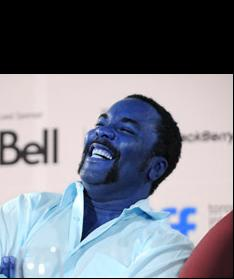

In [15]:
cv2.imread(f"{BASE_DIR}//imdb-clean-1024//imdb-clean-1024//{p}")

array([[[  0,   0,   0],
        [  0,   0,   0],
        [  0,   0,   0],
        ...,
        [  0,   0,   0],
        [  0,   0,   0],
        [  0,   0,   0]],

       [[  0,   0,   0],
        [  0,   0,   0],
        [  0,   0,   0],
        ...,
        [  0,   0,   0],
        [  0,   0,   0],
        [  0,   0,   0]],

       [[  0,   0,   0],
        [  0,   0,   0],
        [  0,   0,   0],
        ...,
        [  0,   0,   0],
        [  0,   0,   0],
        [  0,   0,   0]],

       ...,

       [[225, 199, 148],
        [216, 190, 137],
        [225, 195, 145],
        ...,
        [ 25,  23,  35],
        [ 26,  25,  32],
        [  3,   2,   8]],

       [[212, 197, 155],
        [210, 194, 152],
        [214, 195, 155],
        ...,
        [ 24,  23,  30],
        [ 18,  17,  23],
        [  1,   1,   5]],

       [[ 31,  24,  19],
        [ 38,  31,  20],
        [ 41,  31,  20],
        ...,
        [  3,   3,   7],
        [  7,   7,   9],
        [  0,   0,   2]]], dtype=uint8)
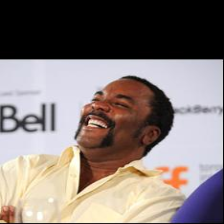

In [16]:
format_image(p)

In [17]:
full_paths = df["filename"].apply(lambda x: BASE_DIR + CHILD_DIR +'//'+ str(x)).values
# 3. Create a fast, memory-mapped function using native TensorFlow operations
def load_and_format(file_path):
    img = tf.io.read_file(file_path)
    img = tf.image.decode_jpeg(img, channels=3)  # Decodes image
    img = tf.image.resize(img, [224, 224])
    return img

# 4. Build a streaming dataset pipeline (Uses almost 0 GB of RAM)
dataset = tf.data.Dataset.from_tensor_slices(full_paths)
dataset = dataset.map(load_and_format, num_parallel_calls=tf.data.AUTOTUNE)



In [18]:
full_paths = df_test["filename"].apply(lambda x: BASE_DIR + CHILD_DIR +'//'+ str(x)).values
x_test = tf.data.Dataset.from_tensor_slices(full_paths)
x_test = x_test.map(load_and_format, num_parallel_calls=tf.data.AUTOTUNE)

In [19]:
full_paths = df_val["filename"].apply(lambda x: BASE_DIR + CHILD_DIR +'//'+ str(x)).values
x_val = tf.data.Dataset.from_tensor_slices(full_paths)
x_val = x_val.map(load_and_format, num_parallel_calls=tf.data.AUTOTUNE)

In [20]:
for img in dataset.take(1):
    print(img.numpy().shape)

(224, 224, 3)


In [21]:
import matplotlib.pyplot as plt

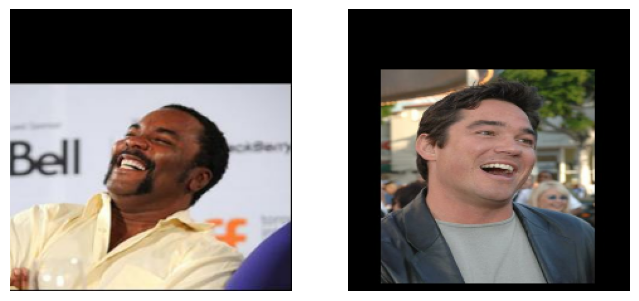

In [22]:
plt.figure(figsize=(8, 4))
for i, img in enumerate(dataset.take(2)):
    plt.subplot(1, 2, i + 1)
    plt.imshow(img.numpy().astype("uint8"))
    plt.axis('off')
plt.show()

In [23]:
y_train =  df["age"]
y_test = df_test["age"]
y_val = df_val["age"]

In [24]:
from tensorflow.keras.applications import MobileNet

In [25]:
import tensorflow.keras.layers as L

In [26]:
model = tf.keras.Sequential([
    L.Rescaling(scale=1./127.5, offset=-1., input_shape=(224, 224, 3)),
    MobileNet(include_top=False,
              pooling='avg',
              weights='imagenet'),
              L.Dense(1)
    ])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
/tmp/ipykernel_1044/679240491.py:3: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  MobileNet(include_top=False,


17225924/17225924 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


In [27]:
model.compile(optimizer='adam', loss='mae', metrics=['mse'])

In [28]:
train_dataset = tf.data.Dataset.zip((dataset, tf.data.Dataset.from_tensor_slices(y_train)))
train_dataset = train_dataset.shuffle(1000).batch(64).prefetch(tf.data.AUTOTUNE)

In [29]:
val_dataset = tf.data.Dataset.zip((x_val, tf.data.Dataset.from_tensor_slices(y_val)))
val_dataset = val_dataset.batch(64).prefetch(tf.data.AUTOTUNE)

In [30]:
test_dataset = tf.data.Dataset.zip((x_test, tf.data.Dataset.from_tensor_slices(y_test)))
test_dataset = test_dataset.batch(64).prefetch(tf.data.AUTOTUNE)

In [32]:
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)
checkpoint = tf.keras.callbacks.ModelCheckpoint(
    "best_model.keras",
    monitor='val_loss',
    save_best_only=True
)

history = model.fit(train_dataset,
          epochs=9,
          validation_data=val_dataset,
          callbacks=[early_stop, checkpoint])

Epoch 1/9
2874/2874 ━━━━━━━━━━━━━━━━━━━━ 726s 252ms/step - loss: 6.3836 - mse: 72.4673 - val_loss: 6.3814 - val_mse: 70.4642
Epoch 2/9
2874/2874 ━━━━━━━━━━━━━━━━━━━━ 691s 240ms/step - loss: 5.5861 - mse: 55.0949 - val_loss: 6.4440 - val_mse: 71.6522
Epoch 3/9
2874/2874 ━━━━━━━━━━━━━━━━━━━━ 685s 238ms/step - loss: 5.2085 - mse: 48.4042 - val_loss: 5.7266 - val_mse: 58.2545
Epoch 4/9
2874/2874 ━━━━━━━━━━━━━━━━━━━━ 799s 257ms/step - loss: 4.9291 - mse: 43.7907 - val_loss: 5.6228 - val_mse: 55.3897
Epoch 5/9
2874/2874 ━━━━━━━━━━━━━━━━━━━━ 700s 243ms/step - loss: 4.6671 - mse: 39.6482 - val_loss: 7.0901 - val_mse: 84.3078
Epoch 6/9
2874/2874 ━━━━━━━━━━━━━━━━━━━━ 740s 257ms/step - loss: 4.4489 - mse: 36.3576 - val_loss: 5.5216 - val_mse: 53.8089
Epoch 7/9
2874/2874 ━━━━━━━━━━━━━━━━━━━━ 697s 242ms/step - loss: 4.2354 - mse: 33.2510 - val_loss: 5.9699 - val_mse: 62.6952
Epoch 8/9
2874/2874 ━━━━━━━━━━━━━━━━━━━━ 696s 242ms/step - loss: 4.0625 - mse: 30.7280 - val_loss: 5.4718 - val_mse: 53.7304


In [33]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [34]:
model.save("/content/drive/MyDrive/facial_age_model.keras")

In [35]:
test_loss = model.evaluate(test_dataset)


877/877 ━━━━━━━━━━━━━━━━━━━━ 136s 155ms/step - loss: 5.9307 - mse: 62.1088


TypeError: unsupported format string passed to list.__format__

In [50]:
test_loss

[5.930717468261719, 62.1087760925293]

INFERENCE

In [46]:
img = "path"
img = load_and_format(img)  # or load_and_format — shape (128, 128, 3)
img = tf.expand_dims(img, axis=0)  # shape becomes (1, 128, 128, 3)
prediction = model.predict(img)
age = prediction[0][0]
print(f"Predicted age: {age:.1f}")

In [49]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenet_1.00_224 (Functional) │ (None, 1024)           │     3,228,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │         1,025 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,645,893 (36.80 MB)

 Trainable params: 3,208,001 (12.24 MB)

 Non-trainable params: 21,888 (85.50 KB)

 Optimizer params: 6,416,004 (24.48 MB)

In [51]:
import tensorflow as tf
print(tf.__version__)

2.20.0
